# 02 — ConvLSTM (Channel 1)

Used four Channel 1 satellite images, spaced exactly three hours apart, to predict the six-hour-ahead target wind speed (`TARGET_WIND`) at the final image timestamp.


- Parquet labels: `/content/data/samples_6h`
- Satellite patches: `/content/data/patches_full`
- Each patch contains two 64 × 64 channels stored as `float16`; this experiment uses Channel 1 (`image[0]`).
- Four input images must be exactly 3 hours apart (a 9-hour window ending at the prediction timestamp).
- The target is the `TARGET_WIND` value associated with the final image timestamp.
- Existing split names are `1_train`, `2_val`, and `3_test`.

## 1. Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Extract the dataset archive


In [2]:
import os
import tarfile

archive = "/content/drive/MyDrive/cyclone/cyclone_data.tar.gz"
data_root = "/content/data"
required_dirs = [
    os.path.join(data_root, "samples_6h"),
    os.path.join(data_root, "patches_full"),
]

if all(os.path.isdir(p) for p in required_dirs):
    print("Dataset folders already exist. Skipping extraction.")
else:
    if not os.path.isfile(archive):
        raise FileNotFoundError(
            f"Could not find {archive}. Check MyDrive/cyclone."
        )
    os.makedirs(data_root, exist_ok=True)
    with tarfile.open(archive, "r:gz") as tar:
        # Python's data filter avoids extracting unsafe archive paths.
        tar.extractall(path=data_root, filter="data")
    print("Extraction completed.")

for p in required_dirs:
    print(p, "exists:", os.path.isdir(p))

Extraction completed.
/content/data/samples_6h exists: True
/content/data/patches_full exists: True


## 3. Load the Parquet datasets

In [3]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

labels_path = "/content/data/samples_6h"
patches_path = "/content/data/patches_full"

print("Label parquet files:", len(glob.glob(os.path.join(labels_path, "*.parquet"))))
print("Patch parquet files:", len(glob.glob(os.path.join(patches_path, "*.parquet"))))

L = pd.read_parquet(labels_path)
P = pd.read_parquet(patches_path)

L["ISO_TIME"] = pd.to_datetime(L["ISO_TIME"], errors="coerce")
P["T"] = pd.to_datetime(P["T"], errors="coerce")

print("Labels shape:", L.shape)
print("Patches shape:", P.shape)
print("Label columns:", L.columns.tolist())
print("Patch columns:", P.columns.tolist())
print("\nLabel split counts:")
print(L["SPLIT"].value_counts(dropna=False))

Label parquet files: 1
Patch parquet files: 1155
Labels shape: (4295, 8)
Patches shape: (10814, 5)
Label columns: ['SID', 'BASIN', 'ISO_TIME', 'LAT', 'LON', 'WIND_KT', 'TARGET_WIND', 'SPLIT']
Patch columns: ['SID', 'T', 'LAT', 'LON', 'PATCH']

Label split counts:
SPLIT
1_train    2806
3_test     1013
2_val       476
Name: count, dtype: int64


## 4. Assign each satellite patch to its existing cyclone split

In [4]:
cyclone_split_lookup = L[["SID", "SPLIT"]].drop_duplicates()
split_counts = cyclone_split_lookup.groupby("SID")["SPLIT"].nunique()

multi_split = int((split_counts > 1).sum())
print("Unique cyclones:", cyclone_split_lookup["SID"].nunique())
print("Cyclones assigned to multiple splits:", multi_split)

if multi_split:
    raise ValueError(
        "Some cyclones appear in multiple splits. Resolve split assignments "
        "before training to avoid data leakage."
    )

P_split = P.merge(
    cyclone_split_lookup,
    on="SID",
    how="left",
    validate="many_to_one"
)
P_split = P_split[
    P_split["SPLIT"].isin(["1_train", "2_val", "3_test"])
].copy()

print("\nPatches by split:")
print(P_split["SPLIT"].value_counts())
print("Patches without a recognized split:", int(P["SID"].nunique() - P_split["SID"].nunique()))

Unique cyclones: 311
Cyclones assigned to multiple splits: 0

Patches by split:
SPLIT
1_train    7174
3_test     2691
2_val       949
Name: count, dtype: int64
Patches without a recognized split: 0


## 5. Prepare Channel 1 images

In [5]:
channel1_records = []
skipped_images = 0
bad_shape_images = 0

for row in P_split.itertuples(index=False):
    values = np.frombuffer(row.PATCH, dtype=np.float16)

    if values.size != 2 * 64 * 64:
        bad_shape_images += 1
        continue

    two_channels = values.reshape(2, 64, 64)
    channel1 = two_channels[0].astype(np.float32)

    # Skip images whose Channel 1 pixels are all missing or non-finite.
    if not np.isfinite(channel1).any():
        skipped_images += 1
        continue

    channel1_records.append({
        "SID": row.SID,
        "T": row.T,
        "SPLIT": row.SPLIT,
        "IMAGE": channel1
    })

channel1_df = pd.DataFrame(channel1_records)

print("Original patches in recognized splits:", len(P_split))
print("Prepared Channel 1 images:", len(channel1_df))
print("Completely missing images skipped:", skipped_images)
print("Unexpected patch sizes skipped:", bad_shape_images)
print("\nImages by split:")
print(channel1_df["SPLIT"].value_counts())
print("\nExample image shape:", channel1_df.iloc[0]["IMAGE"].shape)
print(
    "Non-finite pixels in prepared images:",
    int(sum((~np.isfinite(img)).sum() for img in channel1_df["IMAGE"]))
)

Original patches in recognized splits: 10814
Prepared Channel 1 images: 10811
Completely missing images skipped: 3
Unexpected patch sizes skipped: 0

Images by split:
SPLIT
1_train    7171
3_test     2691
2_val       949
Name: count, dtype: int64

Example image shape: (64, 64)
Non-finite pixels in prepared images: 0


## 6. Build four-image sequences and match future wind-speed targets

In [6]:
# TARGET_WIND at the final image timestamp is the prediction target.
label_targets = L[["SID", "ISO_TIME", "TARGET_WIND"]].dropna(
    subset=["SID", "ISO_TIME", "TARGET_WIND"]
).copy()

duplicate_keys = int(label_targets.duplicated(["SID", "ISO_TIME"]).sum())
print("Duplicate (SID, ISO_TIME) target rows:", duplicate_keys)

if duplicate_keys:
    raise ValueError(
        "Duplicate target rows exist for a cyclone/timestamp. "
        "Inspect the labels before creating sequences."
    )

label_lookup = label_targets.set_index(["SID", "ISO_TIME"])["TARGET_WIND"]
sequence_records = []

for sid, group in channel1_df.groupby("SID"):
    group = group.sort_values("T").reset_index(drop=True)

    for i in range(3, len(group)):
        window = group.iloc[i-3:i+1]
        times = window["T"].tolist()
        endpoint_time = times[-1]

        expected_times = [
            endpoint_time - pd.Timedelta(hours=9),
            endpoint_time - pd.Timedelta(hours=6),
            endpoint_time - pd.Timedelta(hours=3),
            endpoint_time
        ]

        # Require four consecutive images, exactly 3 hours apart.
        if times != expected_times:
            continue

        # Do not allow a sequence to cross train/validation/test splits.
        if window["SPLIT"].nunique() != 1:
            continue

        key = (sid, endpoint_time)
        if key not in label_lookup.index:
            continue

        target_wind = float(label_lookup.loc[key])
        if not np.isfinite(target_wind):
            continue

        sequence_records.append({
            "SID": sid,
            "END_TIME": endpoint_time,
            "SPLIT": window.iloc[-1]["SPLIT"],
            "TARGET_WIND": target_wind,
            "IMAGES": window["IMAGE"].tolist()
        })

sequences_df = pd.DataFrame(sequence_records)

if sequences_df.empty:
    raise ValueError(
        "No valid sequences were created. Check timestamps, split assignments, "
        "and label matching."
    )

print("Valid four-image sequences:", len(sequences_df))
print("\nSequences by split:")
print(sequences_df["SPLIT"].value_counts())
print("\nTarget wind-speed summary (knots):")
print(sequences_df["TARGET_WIND"].describe())
print("\nExample sequence:")
display(sequences_df[["SID", "END_TIME", "SPLIT", "TARGET_WIND"]].head())

Duplicate (SID, ISO_TIME) target rows: 0
Valid four-image sequences: 4286

Sequences by split:
SPLIT
1_train    2797
3_test     1013
2_val       476
Name: count, dtype: int64

Target wind-speed summary (knots):
count    4286.000000
mean       48.831078
std        24.543903
min        15.000000
25%        30.000000
50%        40.000000
75%        60.000000
max       165.000000
Name: TARGET_WIND, dtype: float64

Example sequence:


,SID,END_TIME,SPLIT,TARGET_WIND
0,2016138N10081,2016-05-17 21:00:00,1_train,30.0
1,2016138N10081,2016-05-18 00:00:00,1_train,30.0
2,2016138N10081,2016-05-18 06:00:00,1_train,30.0
3,2016138N10081,2016-05-18 12:00:00,1_train,30.0
4,2016138N10081,2016-05-18 18:00:00,1_train,35.0


## 7. Calculate normalization statistics using training pixels only

In [7]:
train_sequences = sequences_df[sequences_df["SPLIT"] == "1_train"]
if train_sequences.empty:
    raise ValueError("No training sequences were created.")

# Use the training split's valid pixels only; ignore missing pixels in statistics.
pixel_sum = 0.0
pixel_squared_sum = 0.0
pixel_count = 0

for _, row in train_sequences.iterrows():
    for image in row["IMAGES"]:
        valid = image[np.isfinite(image)].astype(np.float64)
        pixel_sum += valid.sum()
        pixel_squared_sum += np.square(valid).sum()
        pixel_count += valid.size

if pixel_count == 0:
    raise ValueError("No finite training pixels available for normalization.")

train_mean = pixel_sum / pixel_count
train_variance = max(pixel_squared_sum / pixel_count - train_mean**2, 0.0)
train_std = float(np.sqrt(train_variance))

if not np.isfinite(train_std) or train_std == 0:
    raise ValueError(f"Invalid training pixel standard deviation: {train_std}")

print("Finite training pixels:", pixel_count)
print("Training pixel mean:", train_mean)
print("Training pixel standard deviation:", train_std)

Finite training pixels: 45826048
Training pixel mean: 238.52895445784458
Training pixel standard deviation: 31.757712266880233


## 8. Normalize sequences and prepare model arrays

In [8]:
def normalize_image(image):
    image = image.astype(np.float32).copy()
    # Replace missing pixels with the training mean; after standardization these become 0.
    image[~np.isfinite(image)] = train_mean
    return (image - train_mean) / train_std

arrays = {}

for split_label, split_name in [
    ("1_train", "train"),
    ("2_val", "val"),
    ("3_test", "test")
]:
    part = sequences_df[sequences_df["SPLIT"] == split_label]
    if part.empty:
        raise ValueError(f"No valid sequences for split {split_label}.")

    X = np.stack([
        np.stack([normalize_image(img) for img in images])[..., np.newaxis]
        for images in part["IMAGES"]
    ]).astype(np.float32)

    y = part["TARGET_WIND"].to_numpy(dtype=np.float32)

    arrays[f"X_{split_name}"] = X
    arrays[f"y_{split_name}"] = y

    print(f"{split_name}: X={X.shape}, y={y.shape}")
    print(f"{split_name} non-finite input values:", int((~np.isfinite(X)).sum()))

X_train, y_train = arrays["X_train"], arrays["y_train"]
X_val, y_val = arrays["X_val"], arrays["y_val"]
X_test, y_test = arrays["X_test"], arrays["y_test"]

train: X=(2797, 4, 64, 64, 1), y=(2797,)
train non-finite input values: 0
val: X=(476, 4, 64, 64, 1), y=(476,)
val non-finite input values: 0
test: X=(1013, 4, 64, 64, 1), y=(1013,)
test non-finite input values: 0


## 9. Preview the four input images

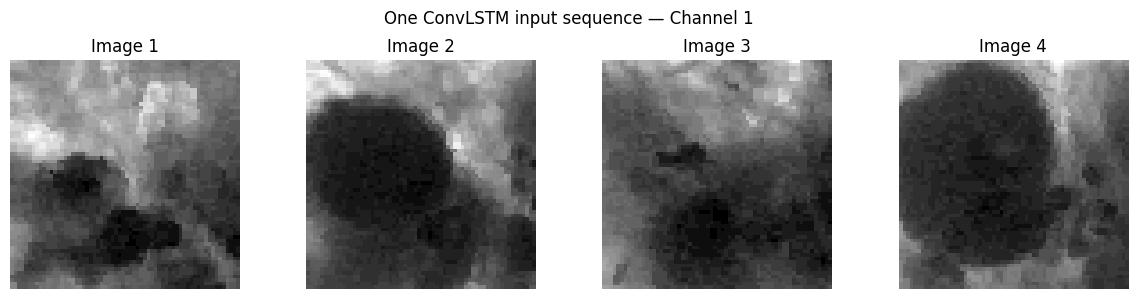

Target wind speed (knots): 30.0


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for idx, ax in enumerate(axes):
    ax.imshow(X_train[0, idx, :, :, 0], cmap="gray")
    ax.set_title(f"Image {idx + 1}")
    ax.axis("off")
plt.suptitle("One ConvLSTM input sequence — Channel 1")
plt.tight_layout()
plt.show()

print("Target wind speed (knots):", float(y_train[0]))

## 10. Build the ConvLSTM model

In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, ConvLSTM2D, BatchNormalization, Conv2D,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

model = Sequential([
    Input(shape=(4, 64, 64, 1)),

    ConvLSTM2D(
        filters=16,
        kernel_size=(3, 3),
        padding="same",
        activation="tanh",
        return_sequences=False
    ),

    BatchNormalization(),

    Conv2D(
        filters=16,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    GlobalAveragePooling2D(),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

model.summary()

TensorFlow version: 2.21.0
GPU available: True


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d (ConvLSTM2D)        │ (None, 64, 64, 16)     │         9,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,817 (50.07 KB)

 Trainable params: 12,785 (49.94 KB)

 Non-trainable params: 32 (128.00 B)

## 11. Train the ConvLSTM

In [11]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 81ms/step - loss: 1172.9773 - mean_absolute_error: 25.6954 - val_loss: 1081.8210 - val_mean_absolute_error: 25.3588 - learning_rate: 0.0010
Epoch 2/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 22s 27ms/step - loss: 505.9759 - mean_absolute_error: 17.1507 - val_loss: 812.4370 - val_mean_absolute_error: 22.4195 - learning_rate: 0.0010
Epoch 3/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 470.1375 - mean_absolute_error: 16.5924 - val_loss: 532.7196 - val_mean_absolute_error: 19.3233 - learning_rate: 0.0010
Epoch 4/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 442.6753 - mean_absolute_error: 15.9972 - val_loss: 627.2422 - val_mean_absolute_error: 20.2381 - learning_rate: 0.0010
Epoch 5/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 435.6010 - mean_absolute_error: 15.9718 - val_loss: 604.8452 - val_mean_absolute_error: 19.7854 - learning_rate: 0.0010
Epoch 6/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 407.8392 - mean_absolute_error

## 12. Plot training history

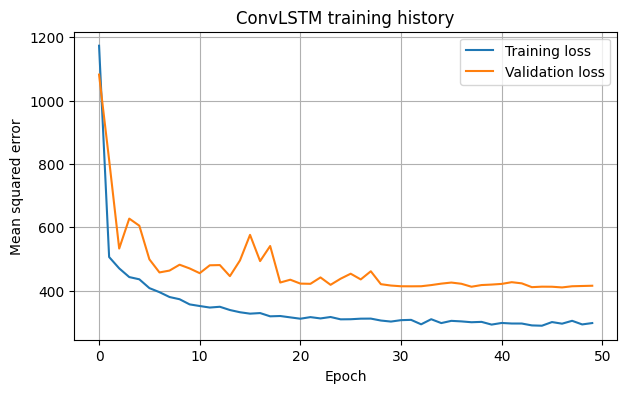

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("ConvLSTM training history")
plt.legend()
plt.grid(True)
plt.show()

## 13. Evaluate on the test set

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

test_predictions = model.predict(X_test, verbose=0).reshape(-1)
test_mae = float(mean_absolute_error(y_test, test_predictions))
test_rmse = float(np.sqrt(mean_squared_error(y_test, test_predictions)))

print("=== CONVLSTM CHANNEL 1 TEST RESULTS ===")
print(f"Test MAE:  {test_mae:.4f} knots")
print(f"Test RMSE: {test_rmse:.4f} knots")

=== CONVLSTM CHANNEL 1 TEST RESULTS ===
Test MAE:  12.5253 knots
Test RMSE: 17.0156 knots


## 14. Save the model, metrics, and test predictions

In [14]:
import json

output_dir = "/content/drive/MyDrive/cyclone/model_results"
os.makedirs(output_dir, exist_ok=True)

model_path = os.path.join(output_dir, "convlstm_channel1_model.keras")
metrics_path = os.path.join(output_dir, "convlstm_channel1_metrics.json")
predictions_path = os.path.join(output_dir, "convlstm_channel1_test_predictions.csv")

model.save(model_path)

metrics = {
    "model": "ConvLSTM",
    "channel": 1,
    "input": "four 64x64 satellite images, 3 hours apart",
    "target": "TARGET_WIND (six-hour-ahead wind speed, knots)",
    "test_samples": int(len(y_test)),
    "test_mae_knots": test_mae,
    "test_rmse_knots": test_rmse,
    "normalization_train_pixel_mean": float(train_mean),
    "normalization_train_pixel_std": float(train_std)
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

test_rows = sequences_df[sequences_df["SPLIT"] == "3_test"][
    ["SID", "END_TIME", "TARGET_WIND"]
].copy().reset_index(drop=True)
test_rows = test_rows.rename(columns={"TARGET_WIND": "actual_wind_knots"})
test_rows["predicted_wind_knots"] = test_predictions
test_rows.to_csv(predictions_path, index=False)

print("Saved model:", model_path)
print("Saved metrics:", metrics_path)
print("Saved test predictions:", predictions_path)
print("\nMetrics:")
print(json.dumps(metrics, indent=2))

Saved model: /content/drive/MyDrive/cyclone/model_results/convlstm_channel1_model.keras
Saved metrics: /content/drive/MyDrive/cyclone/model_results/convlstm_channel1_metrics.json
Saved test predictions: /content/drive/MyDrive/cyclone/model_results/convlstm_channel1_test_predictions.csv

Metrics:
{
  "model": "ConvLSTM",
  "channel": 1,
  "input": "four 64x64 satellite images, 3 hours apart",
  "target": "TARGET_WIND (six-hour-ahead wind speed, knots)",
  "test_samples": 1013,
  "test_mae_knots": 12.525308609008789,
  "test_rmse_knots": 17.015583749376077,
  "normalization_train_pixel_mean": 238.52895445784458,
  "normalization_train_pixel_std": 31.757712266880233
}
